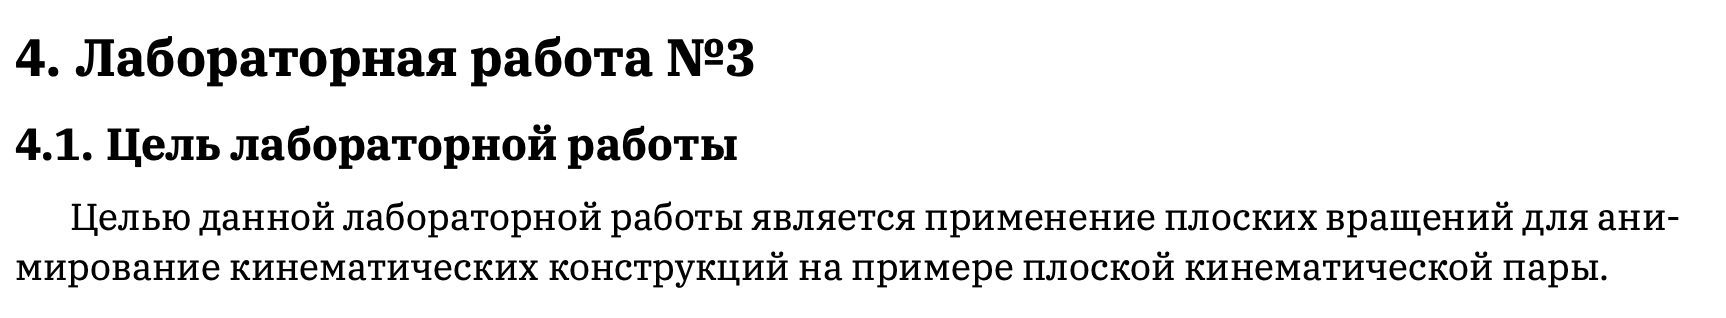

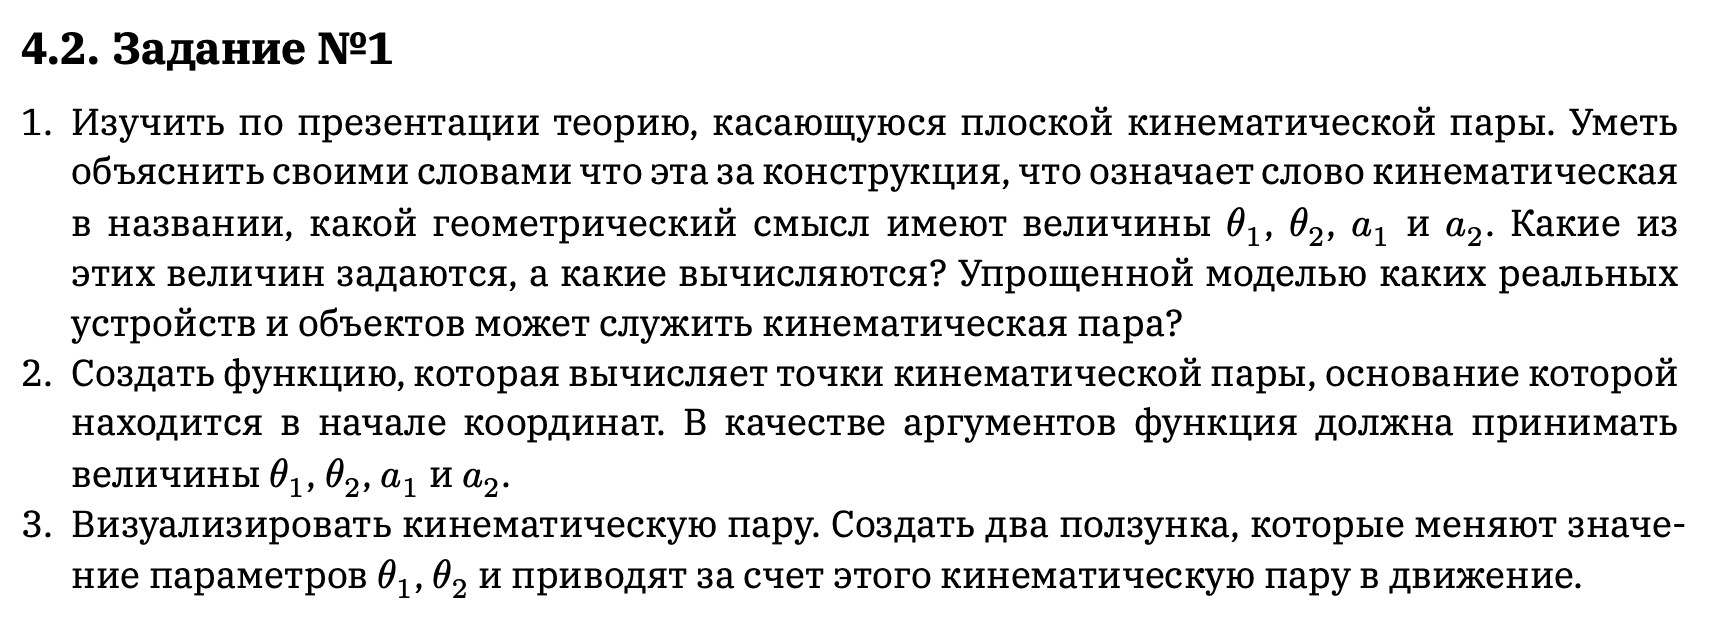

1. Плоская кинематическая пара — это простейшая механическая система из двух звеньев, соединённых подвижным шарниром.

Кинематическая — значит, что речь идёт о движении (кинетика), а не о силах (статике).

Пара — потому что система состоит из двух звеньев.

Геометрический смысл параметров:

- 𝜃₁ — угол между осью Ox и первым звеном (стержнем).
- 𝑎₁ — длина первого звена.
- 𝜃₂ — угол между первым и вторым звеном.
- 𝑎₂ — длина второго звена.

Какие величины задаются, а какие вычисляются?

- Обычно задаются: 𝜃₁, 𝜃₂, 𝑎₁, 𝑎₂ (все четыре).
- Вычисляются: координаты концов звеньев.

Примеры реальных устройств:

- Манипуляторы, роботы, механические руки, простейшие механизмы из двух рычагов.

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, FloatSlider

In [7]:
# 2. Функция для вычисления точек кинематической пары 
def kinematic_pair_points(theta1_deg, theta2_deg, a1, a2):
    """
    Возвращает координаты трёх точек:
    O (начало координат), P1 (конец первого звена), P2 (конец второго звена)
    """
    theta1 = np.radians(theta1_deg)
    theta2 = np.radians(theta2_deg)
    O = np.array([0, 0])
    P1 = np.array([a1 * np.cos(theta1), a1 * np.sin(theta1)])
    P2 = P1 + np.array([a2 * np.cos(theta1 + theta2), a2 * np.sin(theta1 + theta2)])
    return O, P1, P2

In [10]:
# 3. Визуализация с двумя ползунками
def plot_kinematic_pair(theta1=30.0, theta2=60.0, a1=3.0, a2=2.0):
    O, P1, P2 = kinematic_pair_points(theta1, theta2, a1, a2)
    fig, ax = plt.subplots(figsize=(7,7))
    # Первое звено
    ax.plot([O[0], P1[0]], [O[1], P1[1]], 'b-o', label='Первое звено')
    # Второе звено
    ax.plot([P1[0], P2[0]], [P1[1], P2[1]], 'r-o', label='Второе звено')
    # Отметим точки
    ax.text(O[0], O[1], '  O', color='black', fontsize=12)
    ax.text(P1[0], P1[1], '  P1', color='blue', fontsize=12)
    ax.text(P2[0], P2[1], '  P2', color='red', fontsize=12)
    ax.set_aspect('equal')
    ax.set_xlim(-a1-a2-1, a1+a2+1)
    ax.set_ylim(-a1-a2-1, a1+a2+1)
    ax.grid(True)
    ax.legend()
    plt.title(f"Плоская кинематическая пара\n"
              f"θ₁={theta1:.1f}°, θ₂={theta2:.1f}°, a₁={a1:.1f}, a₂={a2:.1f}")
    plt.show()

# Интерактивные ползунки для углов θ₁ и θ₂, длины a₁ и a₂
interact(
    plot_kinematic_pair,
    theta1=FloatSlider(value=30.0, min=0.0, max=180.0, step=1.0, description='θ₁ (°)'),
    theta2=FloatSlider(value=60.0, min=-180.0, max=180.0, step=1.0, description='θ₂ (°)'),
    a1=FloatSlider(value=3.0, min=0.5, max=5.0, step=0.1, description='a₁'),
    a2=FloatSlider(value=2.0, min=0.5, max=5.0, step=0.1, description='a₂')
)

interactive(children=(FloatSlider(value=30.0, description='θ₁ (°)', max=180.0, step=1.0), FloatSlider(value=60…

<function __main__.plot_kinematic_pair(theta1=30.0, theta2=60.0, a1=3.0, a2=2.0)>

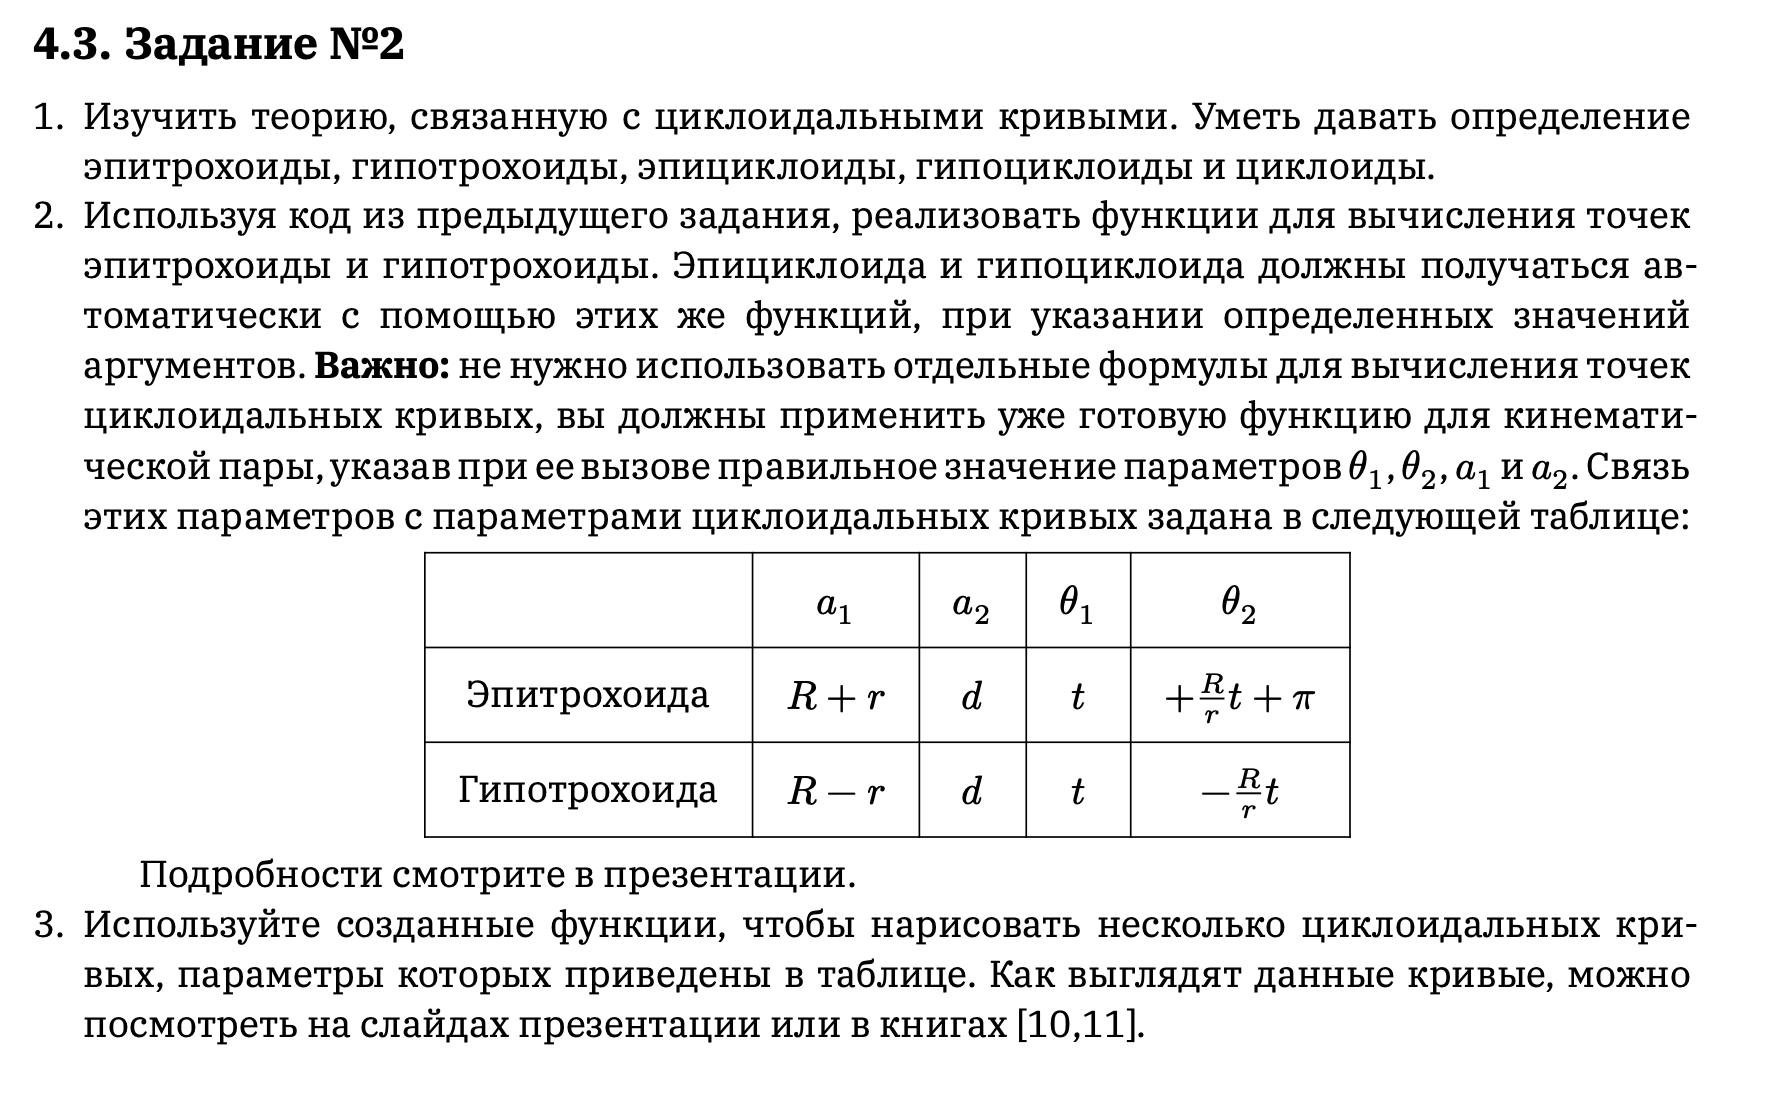

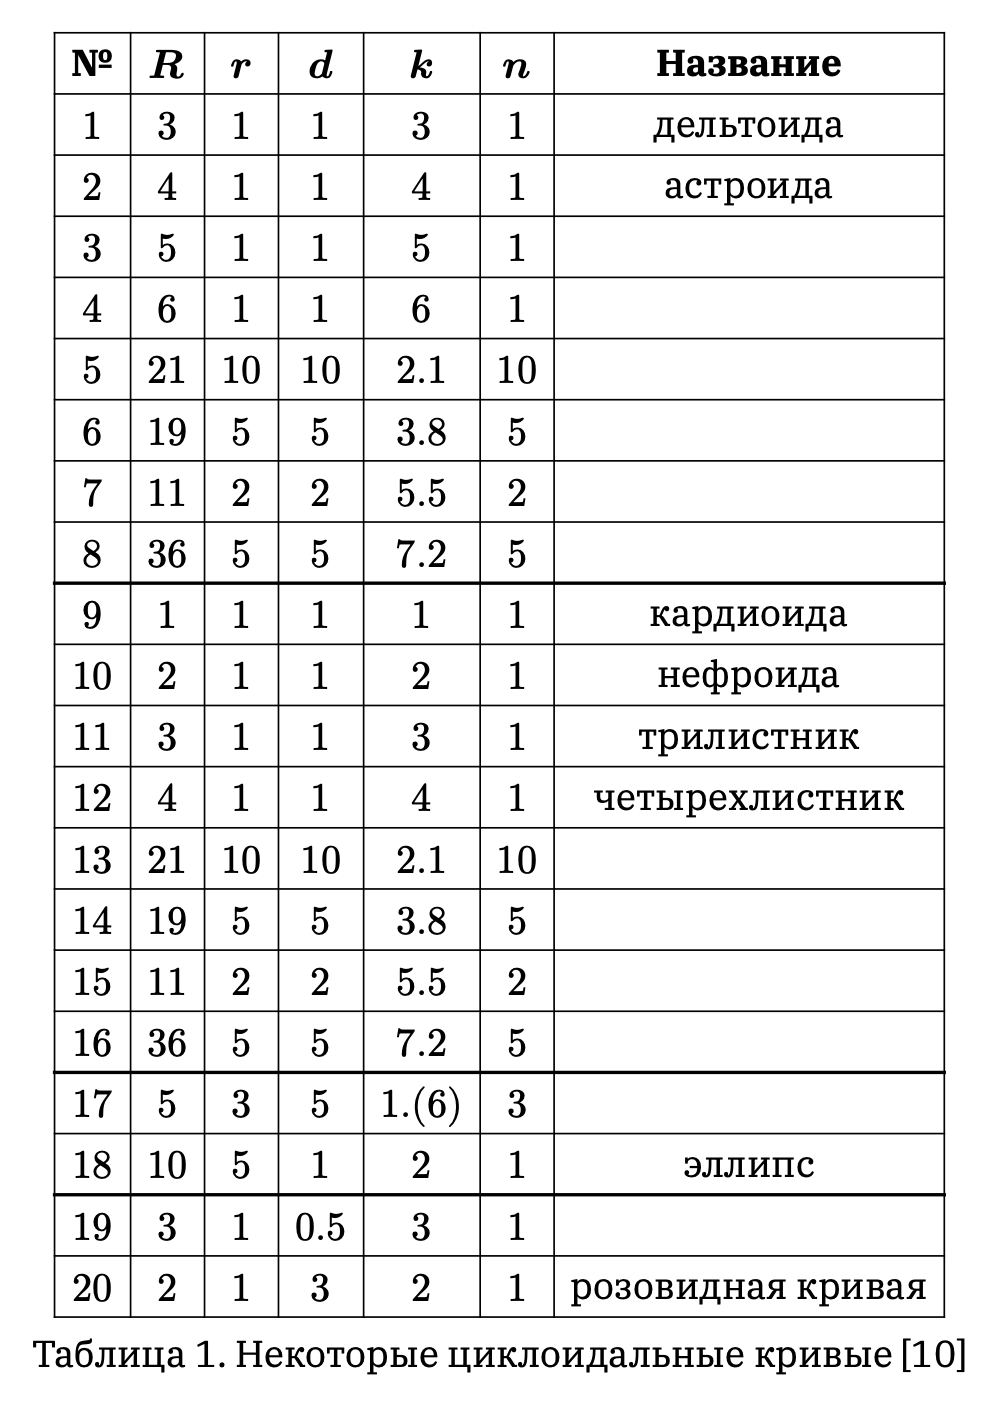

1.
- Циклоида — траектория точки на окружности, катящейся по прямой.
- Эпициклоиды — точка на окружности, катящейся по внешней стороне другой окружности.
- Гипоциклоиды — точка на окружности, катящейся по внутренней стороне другой окружности.
- Эпитрохоиды — как эпициклоиды, но точка не обязательно лежит на окружности, а может быть вне или внутри.
- Гипотрохоиды — как гипоциклоиды, но точка не обязательно лежит на окружности, а может быть вне или внутри.


In [11]:
# 2. Функция для вычисления точек кинематической пары
def kinematic_pair_points_array(theta1, theta2, a1, a2):
    """
    theta1, theta2: массивы углов (рад)
    a1, a2: числа
    Возвращает массив комплексных точек
    """
    P1 = a1 * np.exp(1j * theta1)
    P2 = P1 + a2 * np.exp(1j * (theta1 + theta2))
    return P2

In [12]:
# 3. Функции для эпитрохоиды и гипотрохоиды

def epitrochoid(R, r, d, t):
    a1 = R + r
    a2 = d
    theta1 = t
    theta2 = (R / r) * t
    return kinematic_pair_points_array(theta1, theta2, a1, a2)

def hypotrochoid(R, r, d, t):
    a1 = R - r
    a2 = d
    theta1 = t
    theta2 = - (R / r) * t
    return kinematic_pair_points_array(theta1, theta2, a1, a2)

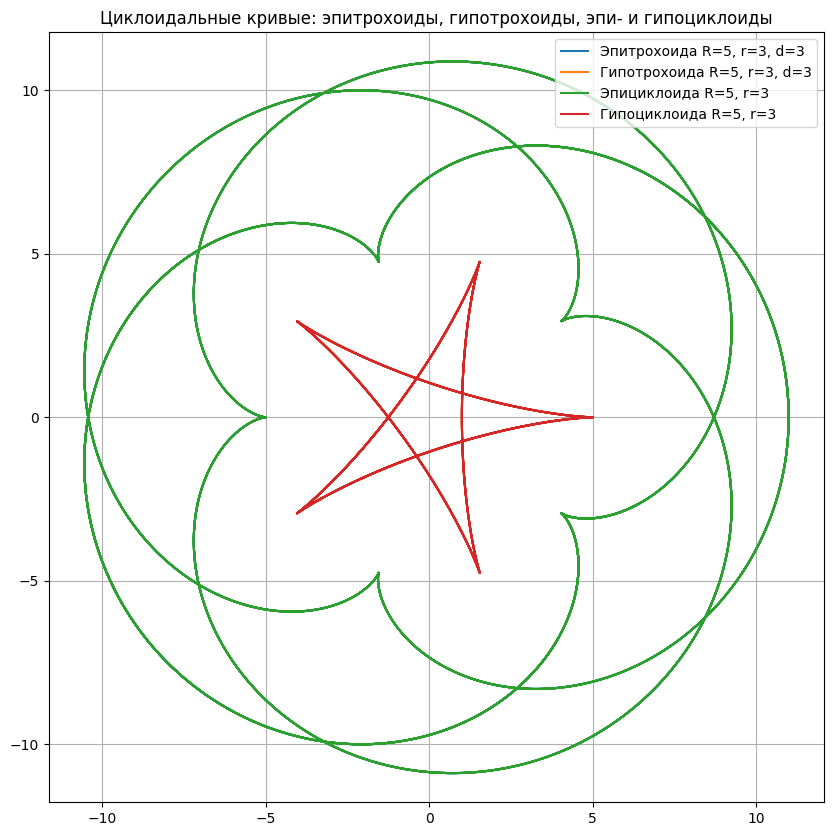

In [14]:
# 4. Визуализация нескольких кривых

t = np.linspace(0, 2 * np.pi * 10, 2000)  # 10 оборотов

plt.figure(figsize=(10, 10))

# Пример 1: Эпитрохоиды
R, r, d = 5, 3, 3
z = epitrochoid(R, r, d, t)
plt.plot(np.real(z), np.imag(z), label=f'Эпитрохоида R={R}, r={r}, d={d}')

# Пример 2: Гипотрохоиды
R, r, d = 5, 3, 3
z = hypotrochoid(R, r, d, t)
plt.plot(np.real(z), np.imag(z), label=f'Гипотрохоида R={R}, r={r}, d={d}')

# Пример 3: Эпициклоида (d = r)
R, r, d = 5, 3, 3
z = epitrochoid(R, r, r, t)
plt.plot(np.real(z), np.imag(z), label=f'Эпициклоида R={R}, r={r}')

# Пример 4: Гипоциклоида (d = r)
R, r, d = 5, 3, 3
z = hypotrochoid(R, r, r, t)
plt.plot(np.real(z), np.imag(z), label=f'Гипоциклоида R={R}, r={r}')

plt.axis('equal')
plt.grid(True)
plt.legend()
plt.title("Циклоидальные кривые: эпитрохоиды, гипотрохоиды, эпи- и гипоциклоиды")
plt.show()

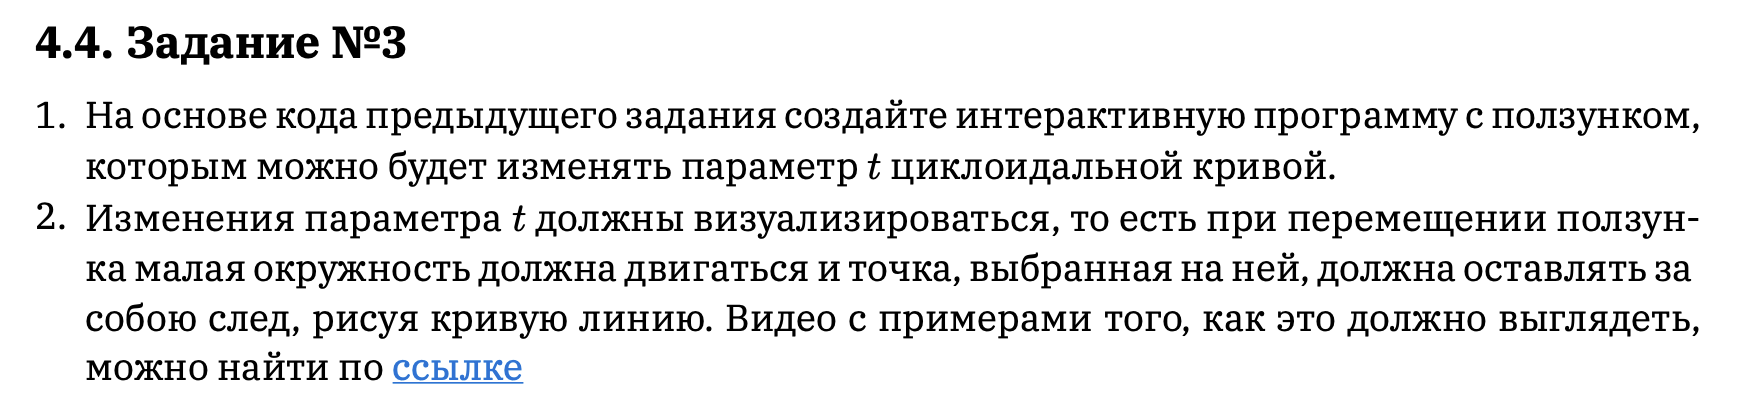

In [15]:
from ipywidgets import interact, FloatSlider

# Функция кинематической пары (из предыдущего задания)
def kinematic_pair_points_array(theta1, theta2, a1, a2):
    P1 = a1 * np.exp(1j * theta1)
    P2 = P1 + a2 * np.exp(1j * (theta1 + theta2))
    return P2, P1

# Эпитрохоиды и гипотрохоиды
def epitrochoid(R, r, d, t):
    a1 = R + r
    a2 = d
    theta1 = t
    theta2 = (R / r) * t
    return kinematic_pair_points_array(theta1, theta2, a1, a2)

def hypotrochoid(R, r, d, t):
    a1 = R - r
    a2 = d
    theta1 = t
    theta2 = - (R / r) * t
    return kinematic_pair_points_array(theta1, theta2, a1, a2)

# Визуализация с анимацией движения малой окружности и следа точки
def plot_cycloid_animation(R=5.0, r=3.0, d=3.0, t_max=2*np.pi*4, t_pos=0.0, family='epitrochoid'):
    # t_pos — текущее положение точки на малой окружности
    t = np.linspace(0, t_pos, 1000)
    if family == 'epitrochoid':
        Z, C = epitrochoid(R, r, d, t)
        # Центр малой окружности
        center_now = (R + r) * np.exp(1j * t_pos)
        # Положение точки на малой окружности
        point_now = center_now + d * np.exp(1j * (t_pos + (R / r) * t_pos))
        # Большая окружность
        big_circle = R * np.exp(1j * np.linspace(0, 2*np.pi, 400))
        # Малая окружность (движущаяся)
        small_circle = r * np.exp(1j * np.linspace(0, 2*np.pi, 400)) + center_now
    else:
        Z, C = hypotrochoid(R, r, d, t)
        center_now = (R - r) * np.exp(1j * t_pos)
        point_now = center_now + d * np.exp(1j * (t_pos - (R / r) * t_pos))
        big_circle = R * np.exp(1j * np.linspace(0, 2*np.pi, 400))
        small_circle = r * np.exp(1j * np.linspace(0, 2*np.pi, 400)) + center_now

    plt.figure(figsize=(8,8))
    # След точки
    plt.plot(np.real(Z), np.imag(Z), 'b-', label='След точки')
    # Большая окружность
    plt.plot(np.real(big_circle), np.imag(big_circle), 'k--', alpha=0.5, label='Большая окружность')
    # Малая окружность
    plt.plot(np.real(small_circle), np.imag(small_circle), 'r-', alpha=0.7, label='Малая окружность')
    # Центр малой окружности
    plt.plot(np.real(center_now), np.imag(center_now), 'ro', label='Центр малой окружности')
    # Текущая точка на малой окружности
    plt.plot(np.real(point_now), np.imag(point_now), 'go', markersize=10, label='Точка на окружности')
    # Соединительная линия
    plt.plot([np.real(center_now), np.real(point_now)], [np.imag(center_now), np.imag(point_now)], 'g--', alpha=0.6)
    plt.axis('equal')
    plt.grid(True)
    plt.legend()
    plt.title(f"{'Эпитрохоида' if family=='epitrochoid' else 'Гипотрохоида'}\nR={R}, r={r}, d={d}, t={t_pos:.2f}")
    plt.show()

# Интерактивный ползунок для t_pos (движение точки)
interact(
    plot_cycloid_animation,
    R=FloatSlider(value=5.0, min=1.0, max=10.0, step=0.1, description='R'),
    r=FloatSlider(value=3.0, min=0.5, max=10.0, step=0.1, description='r'),
    d=FloatSlider(value=3.0, min=0.1, max=10.0, step=0.1, description='d'),
    t_max=FloatSlider(value=8*np.pi, min=2*np.pi, max=20*np.pi, step=np.pi, description='t_max'),
    t_pos=FloatSlider(value=0.0, min=0.0, max=8*np.pi, step=0.01, description='t'),
    family=['epitrochoid', 'hypotrochoid']
)

interactive(children=(FloatSlider(value=5.0, description='R', max=10.0, min=1.0), FloatSlider(value=3.0, descr…

<function __main__.plot_cycloid_animation(R=5.0, r=3.0, d=3.0, t_max=25.132741228718345, t_pos=0.0, family='epitrochoid')>

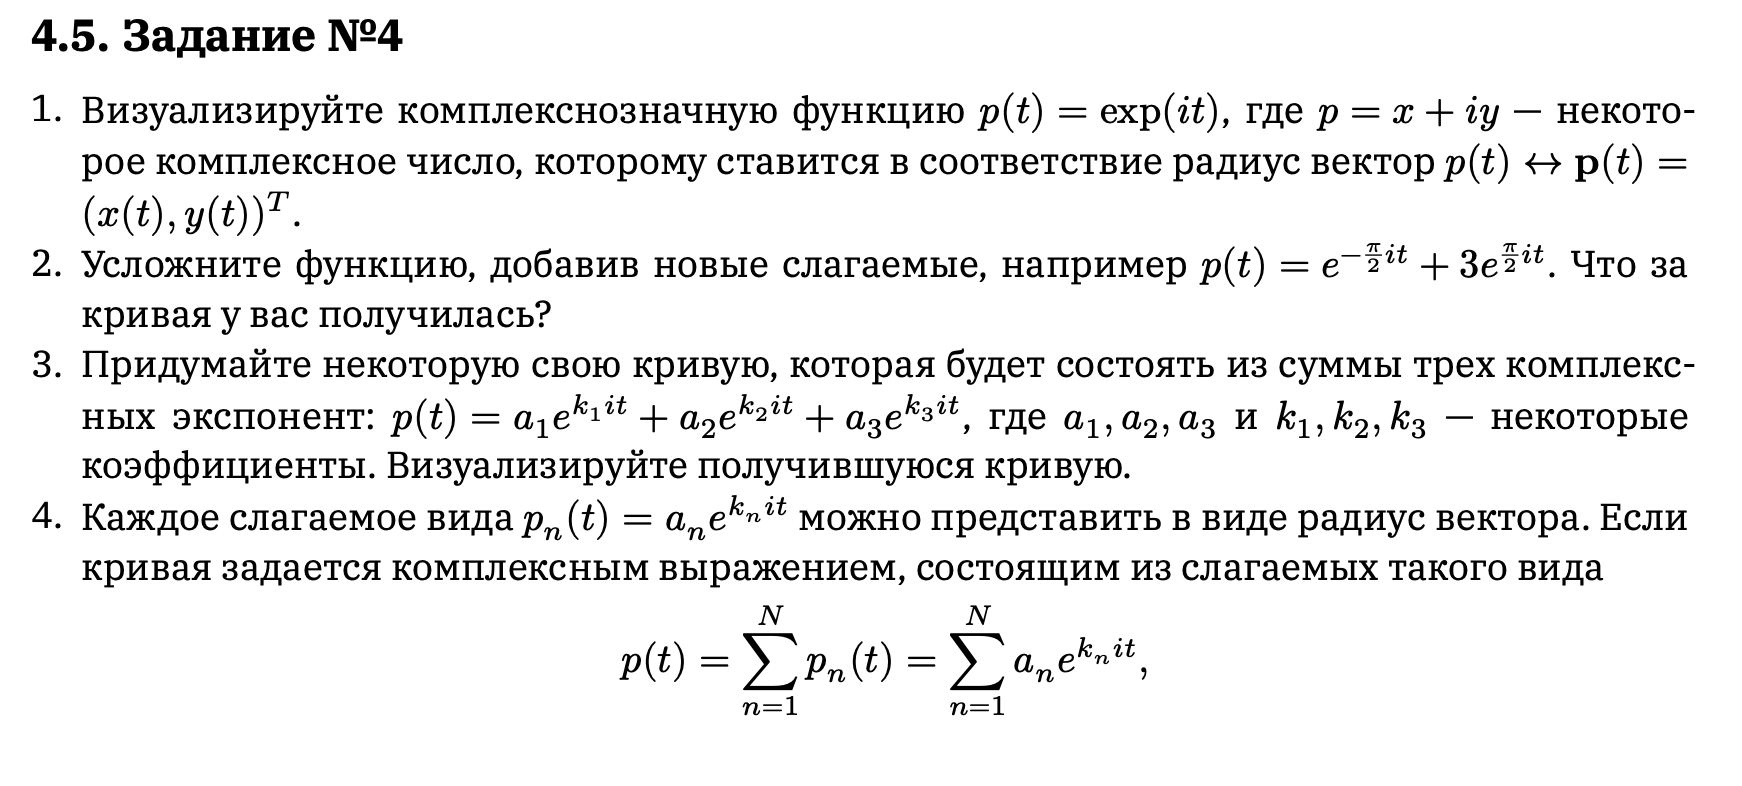
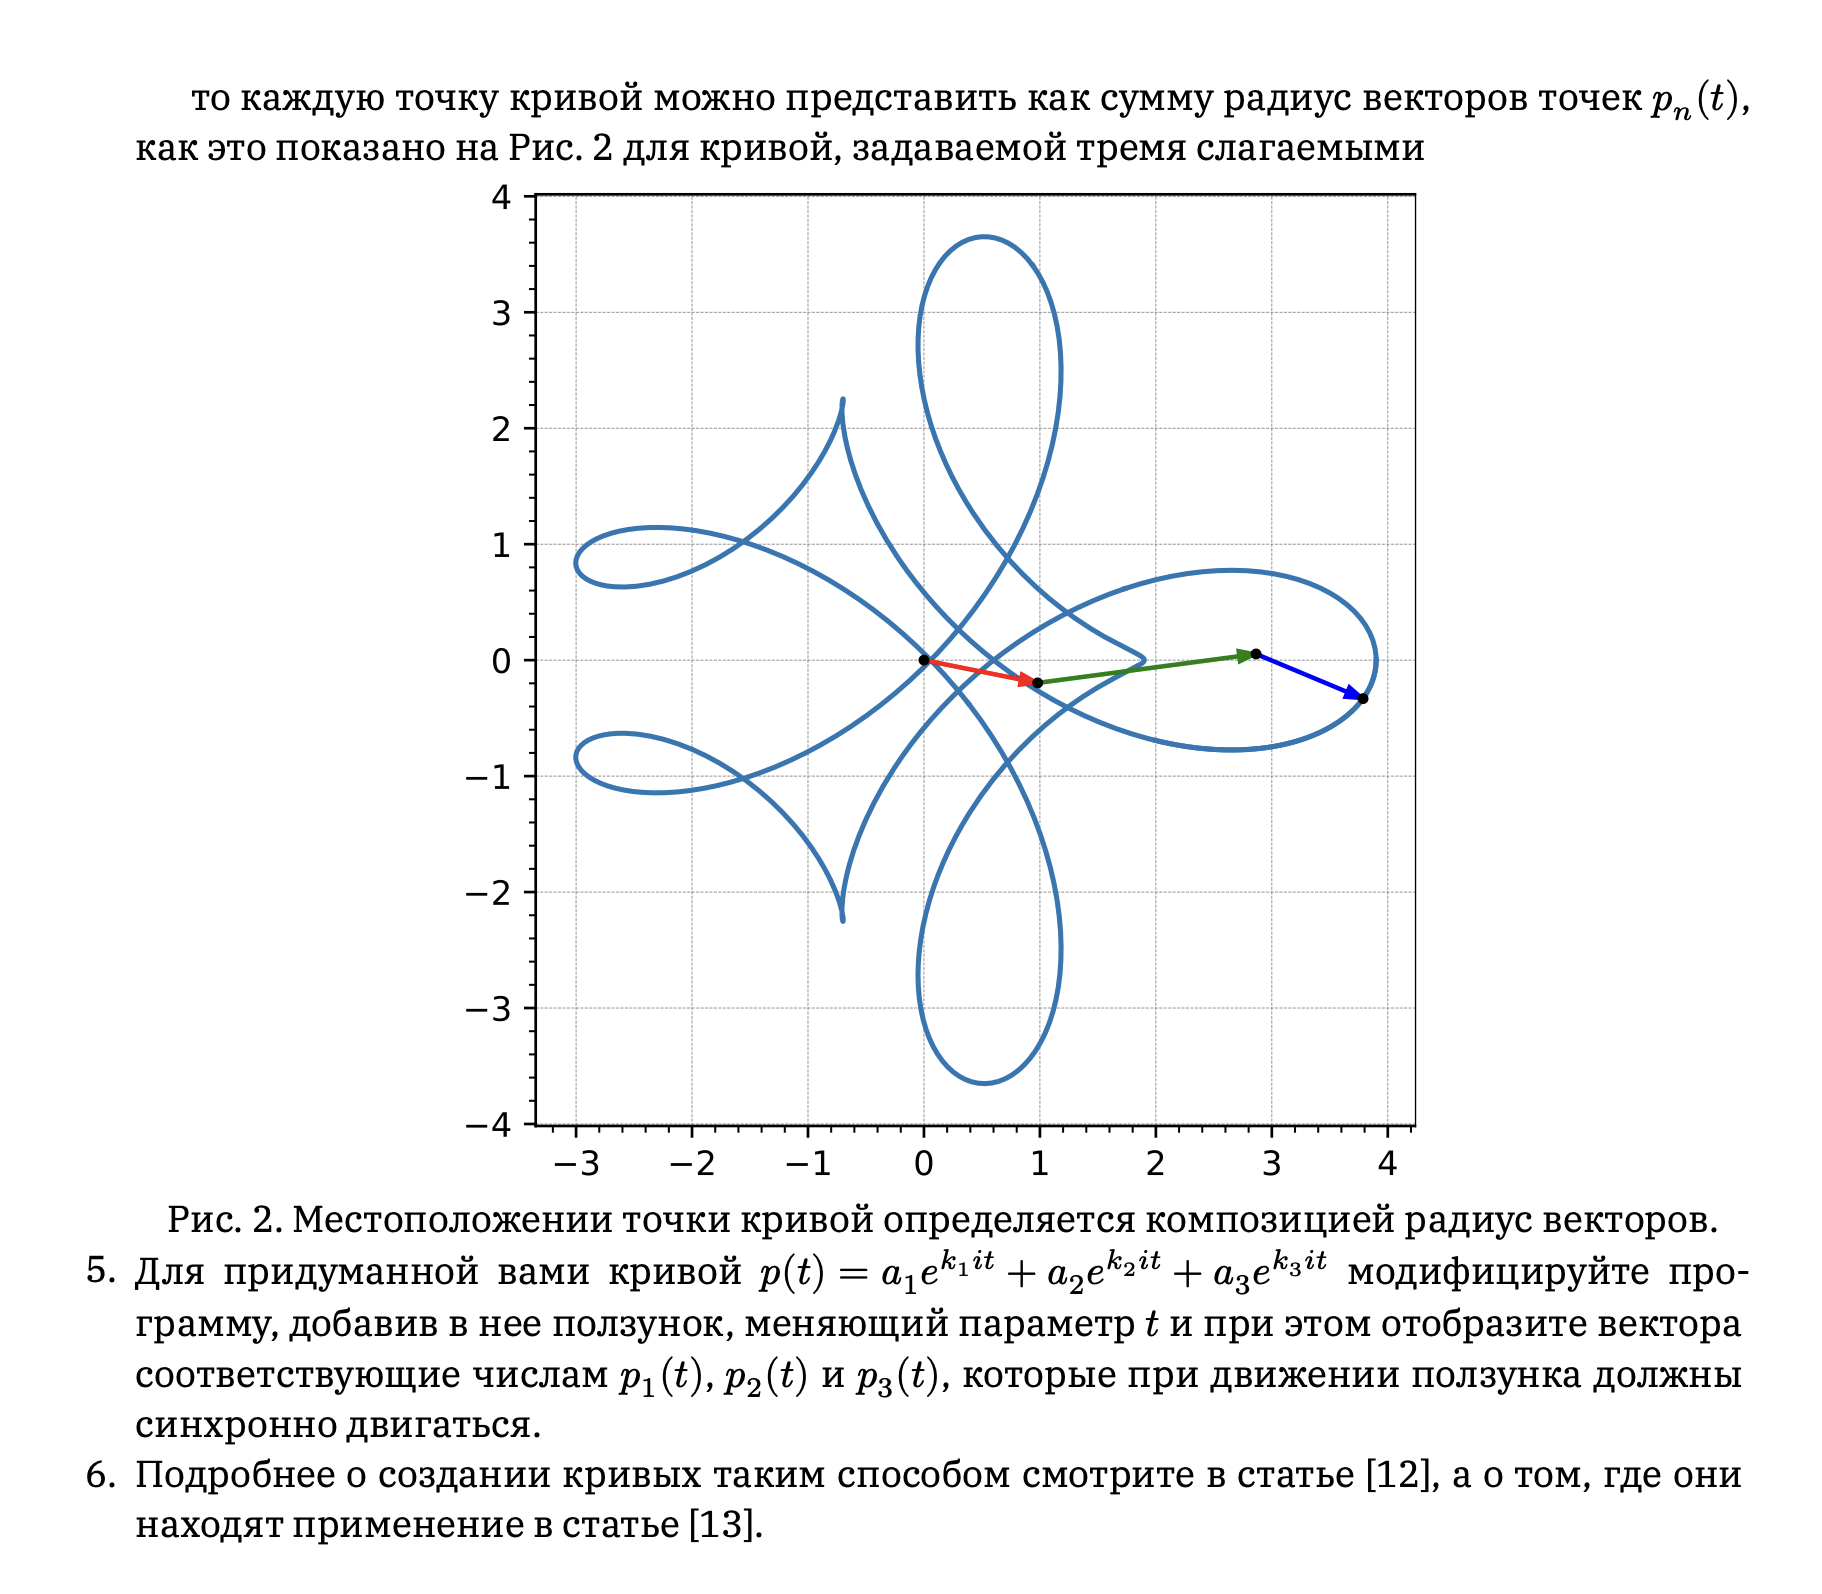

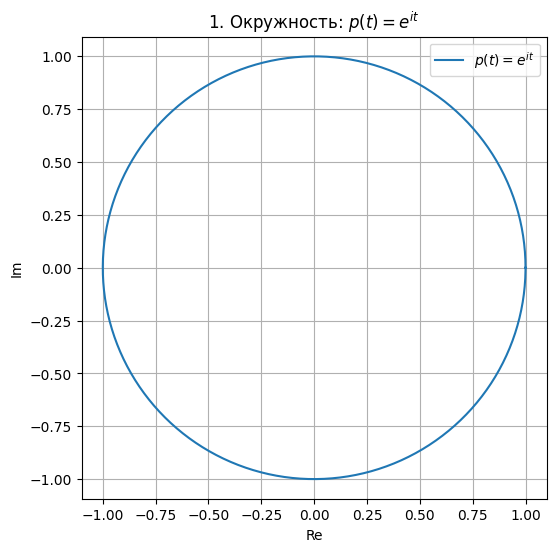

In [17]:
# 1. Визуализация функции $p(t) = e^{it}$

t = np.linspace(0, 2 * np.pi, 500)
p = np.exp(1j * t)

plt.figure(figsize=(6,6))
plt.plot(np.real(p), np.imag(p), label=r'$p(t) = e^{it}$')
plt.axis('equal')
plt.grid(True)
plt.title("1. Окружность: $p(t) = e^{it}$")
plt.xlabel('Re')
plt.ylabel('Im')
plt.legend()
plt.show()

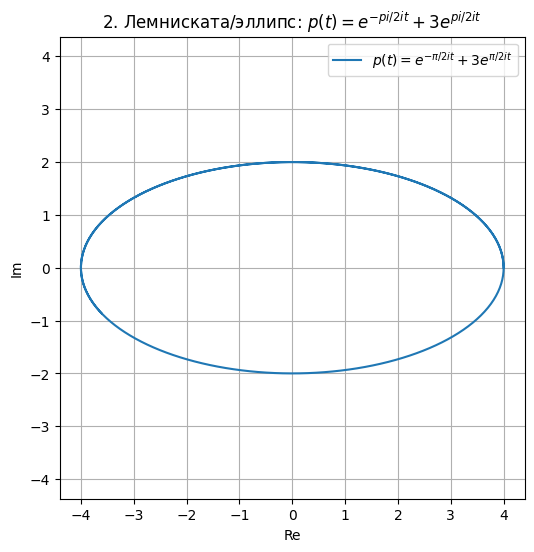

In [21]:
# 2.  Визуализация функции $p(t) = e^{-{\pi}/2 it} + 3e^{{\pi}/2 it}$
p2 = np.exp(-1j * (np.pi/2) * t) + 3 * np.exp(1j * (np.pi/2) * t)

plt.figure(figsize=(6,6))
plt.plot(np.real(p2), np.imag(p2), label=r'$p(t) = e^{-{\pi}/2 it} + 3e^{{\pi}/2 it}$')
plt.axis('equal')
plt.grid(True)
plt.title("2. Лемниската/эллипс: $p(t) = e^{-{pi}/2 it} + 3e^{{pi}/2 it}$")
plt.xlabel('Re')
plt.ylabel('Im')
plt.legend()
plt.show()

# Ответ: Получилась кривая, похожая на эллипс или лемнискату (в зависимости от коэффициентов).

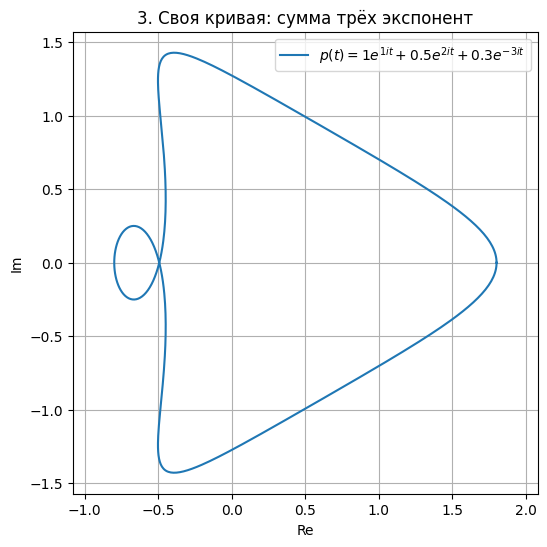

In [24]:
# 3. Своя кривая: сумма трёх комплексных экспонент
# Пример своих коэффициентов
a1, k1 = 1, 1
a2, k2 = 0.5, 2
a3, k3 = 0.3, -3

p3 = a1 * np.exp(1j * k1 * t) + a2 * np.exp(1j * k2 * t) + a3 * np.exp(1j * k3 * t)

plt.figure(figsize=(6,6))
plt.plot(np.real(p3), np.imag(p3), label=fr'$p(t) = {a1}e^{{{k1}it}} + {a2}e^{{{k2}it}} + {a3}e^{{{k3}it}}$')
plt.axis('equal')
plt.grid(True)
plt.title("3. Своя кривая: сумма трёх экспонент")
plt.xlabel('Re')
plt.ylabel('Im')
plt.legend()
plt.show()

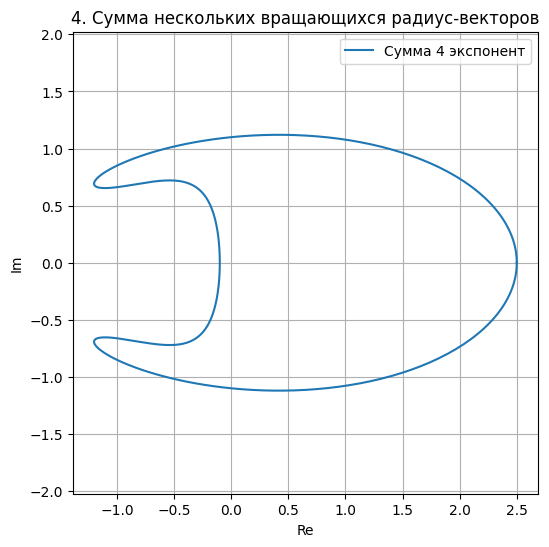

In [25]:
# 4. Геометрический смысл

# Каждое слагаемое  — это вращающийся радиус-вектор длины  с частотой .
#Суммарная кривая — это результат сложения таких вращающихся векторов, как векторная сумма гармоник (аналог Фурье-рядов).

#Визуализация суммы нескольких экспонент:

# Можно добавить еще больше слагаемых
a = [1, 0.7, 0.5, 0.3]
k = [1, 2, -2, 3]
p_sum = sum(a_n * np.exp(1j * k_n * t) for a_n, k_n in zip(a, k))

plt.figure(figsize=(6,6))
plt.plot(np.real(p_sum), np.imag(p_sum), label="Сумма 4 экспонент")
plt.axis('equal')
plt.grid(True)
plt.title("4. Сумма нескольких вращающихся радиус-векторов")
plt.xlabel('Re')
plt.ylabel('Im')
plt.legend()
plt.show()

In [26]:
# Коэффициенты вашей кривой (можно менять!)
a1, k1 = 1, 1
a2, k2 = 0.7, 2
a3, k3 = 0.5, -3

def animate_sum_vectors(t=0.0):
    # Значения векторов
    p1 = a1 * np.exp(1j * k1 * t)
    p2 = a2 * np.exp(1j * k2 * t)
    p3 = a3 * np.exp(1j * k3 * t)
    p_sum = p1 + p2 + p3

    # Для следа кривой
    t_vals = np.linspace(0, t, 500)
    curve = a1 * np.exp(1j * k1 * t_vals) + a2 * np.exp(1j * k2 * t_vals) + a3 * np.exp(1j * k3 * t_vals)

    plt.figure(figsize=(7,7))
    # След кривой
    plt.plot(np.real(curve), np.imag(curve), 'b-', label='След кривой')
    # Векторы
    plt.quiver(0, 0, np.real(p1), np.imag(p1), angles='xy', scale_units='xy', scale=1, color='red', label='p1')
    plt.quiver(np.real(p1), np.imag(p1), np.real(p2), np.imag(p2), angles='xy', scale_units='xy', scale=1, color='green', label='p2')
    plt.quiver(np.real(p1+p2), np.imag(p1+p2), np.real(p3), np.imag(p3), angles='xy', scale_units='xy', scale=1, color='orange', label='p3')
    # Суммарный вектор
    plt.quiver(0, 0, np.real(p_sum), np.imag(p_sum), angles='xy', scale_units='xy', scale=1, color='purple', width=0.01, label='Сумма')
    # Точка на кривой
    plt.plot(np.real(p_sum), np.imag(p_sum), 'ko', markersize=10, label='Текущая точка')
    plt.axis('equal')
    plt.xlim(-3, 3)
    plt.ylim(-3, 3)
    plt.grid(True)
    plt.legend()
    plt.title(r"$p(t) = a_1 e^{k_1 i t} + a_2 e^{k_2 i t} + a_3 e^{k_3 i t}$" + f"\nt = {t:.2f}")
    plt.xlabel('Re')
    plt.ylabel('Im')
    plt.show()

interact(
    animate_sum_vectors,
    t=FloatSlider(value=0.0, min=0.0, max=2*np.pi, step=0.01, description='t')
)

interactive(children=(FloatSlider(value=0.0, description='t', max=6.283185307179586, step=0.01), Output()), _d…

<function __main__.animate_sum_vectors(t=0.0)>